# **ИКБО-62-23 Чекалов А.В. 04.11.2026**
# **1. Самостоятельный раздел по данным fast_food_cheat_meal_workout_burn.csv**

In [1]:
import os
import sys

os.environ["JAVA_HOME"] = r"C:\Program Files\Java\jdk-17"
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["PATH"]

os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["hadoop.home.dir"] = r"C:\hadoop"

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Practice5_Regression")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.adaptive.enabled", "false")
    .config("spark.ui.port", "8088")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")
sc = spark.sparkContext

schema = StructType([
    StructField("order_id", StringType(), False),
    StructField("fast_food_chain", StringType(), False),
    StructField("meal_category", StringType(), False),
    StructField("item_count", IntegerType(), False),
    StructField("total_calories", IntegerType(), False),
    StructField("fat_grams", IntegerType(), False),
    StructField("saturated_fat_grams", IntegerType(), False),
    StructField("carb_grams", IntegerType(), False),
    StructField("sugar_grams", IntegerType(), False),
    StructField("protein_grams", IntegerType(), False),
    StructField("sodium_mg", IntegerType(), False),
    StructField("consumer_gender", StringType(), False),
    StructField("consumer_age", IntegerType(), False),
    StructField("consumer_weight_kg", DoubleType(), False),
    StructField("fitness_level", StringType(), False),
    StructField("thermic_effect_calories", DoubleType(), False),
    StructField("net_caloric_surplus", DoubleType(), False),
    StructField("walking_burn_time_min", DoubleType(), False),
    StructField("cycling_burn_time_min", DoubleType(), False),
    StructField("running_burn_time_min", DoubleType(), False),
    StructField("hiit_burn_time_min", DoubleType(), False),
    StructField("daily_calorie_allowance_pct", DoubleType(), False),
    StructField("workout_shock_tier", StringType(), False)
])

df = spark.read.csv("fast_food_cheat_meal_workout_burn/fast_food_cheat_meal_workout_burn.csv", header=True, schema=schema)
df.printSchema()

df.select("order_id").describe().show()

train_df, valid_df, test_df = df.randomSplit([0.6, 0.2, 0.2], seed=42)
train_df.cache()
valid_df.cache()
test_df.cache()

print(f"Train: {train_df.count()}, Valid: {valid_df.count()}, Test: {test_df.count()}")

C:\Users\lesha\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


root
 |-- order_id: string (nullable = true)
 |-- fast_food_chain: string (nullable = true)
 |-- meal_category: string (nullable = true)
 |-- item_count: integer (nullable = true)
 |-- total_calories: integer (nullable = true)
 |-- fat_grams: integer (nullable = true)
 |-- saturated_fat_grams: integer (nullable = true)
 |-- carb_grams: integer (nullable = true)
 |-- sugar_grams: integer (nullable = true)
 |-- protein_grams: integer (nullable = true)
 |-- sodium_mg: integer (nullable = true)
 |-- consumer_gender: string (nullable = true)
 |-- consumer_age: integer (nullable = true)
 |-- consumer_weight_kg: double (nullable = true)
 |-- fitness_level: string (nullable = true)
 |-- thermic_effect_calories: double (nullable = true)
 |-- net_caloric_surplus: double (nullable = true)
 |-- walking_burn_time_min: double (nullable = true)
 |-- cycling_burn_time_min: double (nullable = true)
 |-- running_burn_time_min: double (nullable = true)
 |-- hiit_burn_time_min: double (nullable = true)
 |

Настроено локальное окружение PySpark и инициализирована сессия для вычислений. Данные загружены с использованием явной схемы (StructType), что гарантирует корректные типы всех признаков. Проверка уникальности order_id подтвердила независимость объектов, поэтому применено случайное разбиение на обучающую (60%), валидационную (20%) и тестовую (20%) выборки с фиксированным seed=42 для воспроизводимости. Все три части закэшированы в памяти для ускорения обучения.

In [2]:
num_cols = ["running_burn_time_min", "total_calories", "consumer_weight_kg", "fat_grams", "sugar_grams"]
train_df.select(num_cols).describe().show()

cat_cols = ["fast_food_chain", "meal_category", "fitness_level"]
for c in cat_cols:
    train_df.groupBy(c).count().orderBy(F.desc("count")).show(5)

+-------+---------------------+-----------------+------------------+-----------------+------------------+
|summary|running_burn_time_min|   total_calories|consumer_weight_kg|        fat_grams|       sugar_grams|
+-------+---------------------+-----------------+------------------+-----------------+------------------+
|  count|                 4901|             4901|              4901|             4901|              4901|
|   mean|   118.73525811058951|1611.242399510304|  77.7437869822488|80.43032034278718| 62.74127729034891|
| stddev|   56.739497036534146|680.1779080039347|14.113813636651308|34.65694692677238|32.140202873279186|
|    min|                 26.3|              750|              48.0|               32|                14|
|    max|                436.5|             3600|             129.4|              190|               175|
+-------+---------------------+-----------------+------------------+-----------------+------------------+

+---------------+-----+
|fast_food_chain|coun

Проведен анализ распределений числовых признаков (среднее, стандартное отклонение, минимумы и максимумы) и частот категориальных переменных. Выявлен широкий разброс целевой переменной (от 26 до 436 минут) и дисбаланс некоторых категорий (например, фитнес-уровня). Полученные статистики подтверждают отсутствие явных аномалий и пригодность исходных данных для подачи в алгоритмы машинного обучения.

In [3]:
target_col = "running_burn_time_min"

drop_cols = [
    "walking_burn_time_min", "cycling_burn_time_min", "hiit_burn_time_min", 
    "workout_shock_tier", "net_caloric_surplus", "thermic_effect_calories", 
    "daily_calorie_allowance_pct", "order_id"
]

train_clean = train_df.drop(*drop_cols).withColumnRenamed(target_col, "label")
valid_clean = valid_df.drop(*drop_cols).withColumnRenamed(target_col, "label")
test_clean = test_df.drop(*drop_cols).withColumnRenamed(target_col, "label")

cat_features = ["fast_food_chain", "meal_category", "consumer_gender", "fitness_level"]
num_features = ["item_count", "total_calories", "fat_grams", "saturated_fat_grams", 
                "carb_grams", "sugar_grams", "protein_grams", "sodium_mg", 
                "consumer_age", "consumer_weight_kg"]

indexers = [StringIndexer(inputCol=c, outputCol=c+"_idx", handleInvalid="keep") for c in cat_features]
encoders = [OneHotEncoder(inputCol=c+"_idx", outputCol=c+"_ohe") for c in cat_features]

assembler_inputs = num_features + [c+"_ohe" for c in cat_features]
assembler = VectorAssembler(inputCols=assembler_inputs, outputCol="features_raw")
scaler = StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True)

Определена целевая переменная running_burn_time_min. Из набора данных удалены 8 колонок, вызывающих утечку целевой информации (время других видов активности, рассчитанный избыток калорий, категория нагрузки), так как они математически связаны с ответом. Создан единый Spark Pipeline, включающий StringIndexer и OneHotEncoder для категорий, VectorAssembler и StandardScaler для числовых признаков. Это гарантирует, что статистики валидации и теста не попадут в процесс обучения.

In [4]:
baseline_mean = train_clean.agg(F.avg("label")).first()[0]

lr = LinearRegression(featuresCol="features", labelCol="label", maxIter=100, regParam=0.1)
rf_50 = RandomForestRegressor(featuresCol="features_raw", labelCol="label", numTrees=50, maxDepth=8, seed=42)
rf_100 = RandomForestRegressor(featuresCol="features_raw", labelCol="label", numTrees=100, maxDepth=10, seed=42)

pipeline_lr = Pipeline(stages=indexers + encoders + [assembler, scaler, lr])
pipeline_rf_50 = Pipeline(stages=indexers + encoders + [assembler, rf_50])
pipeline_rf_100 = Pipeline(stages=indexers + encoders + [assembler, rf_100])

evaluator_rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
evaluator_mae = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="mae")
evaluator_r2 = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")

models = {
    "Linear Regression": pipeline_lr,
    "RF (50 trees)": pipeline_rf_50,
    "RF (100 trees)": pipeline_rf_100
}

results_valid = []
for name, pipeline in models.items():
    model = pipeline.fit(train_clean)
    preds = model.transform(valid_clean)
    rmse = evaluator_rmse.evaluate(preds)
    mae = evaluator_mae.evaluate(preds)
    r2 = evaluator_r2.evaluate(preds)
    results_valid.append((name, rmse, mae, r2))

baseline_preds = valid_clean.withColumn("prediction", F.lit(baseline_mean))
results_valid.append(("Baseline (Mean)", evaluator_rmse.evaluate(baseline_preds), 
                      evaluator_mae.evaluate(baseline_preds), evaluator_r2.evaluate(baseline_preds)))

results_df = pd.DataFrame(results_valid, columns=["Model", "RMSE", "MAE", "R2"]).sort_values("RMSE")
print(results_df.to_string(index=False))

best_model_name = results_df.iloc[0]["Model"]
print(f"Лучшая модель: {best_model_name}")

            Model      RMSE       MAE        R2
   RF (100 trees)  7.737227  5.496840  0.979270
    RF (50 trees)  9.378147  6.518852  0.969545
Linear Regression 10.935792  7.519262  0.958588
  Baseline (Mean) 53.757896 42.619175 -0.000704
Лучшая модель: RF (100 trees)


Обучены три модели (линейная регрессия и случайные леса на 50 и 100 деревьях), а также рассчитано базовое правило (предсказание среднего значения). Сравнение на валидационной выборке показало, что случайный лес на 100 деревьях дает наилучшее качество (RMSE = 7.73, R² = 0.979), превосходя базовый прогноз более чем в 7 раз. Это обосновывает выбор данной модели для финальной проверки.

Test RMSE: 7.607771233711075
Test MAE: 5.4283743641455
Test R2: 0.979479307080203


C:\Users\lesha\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


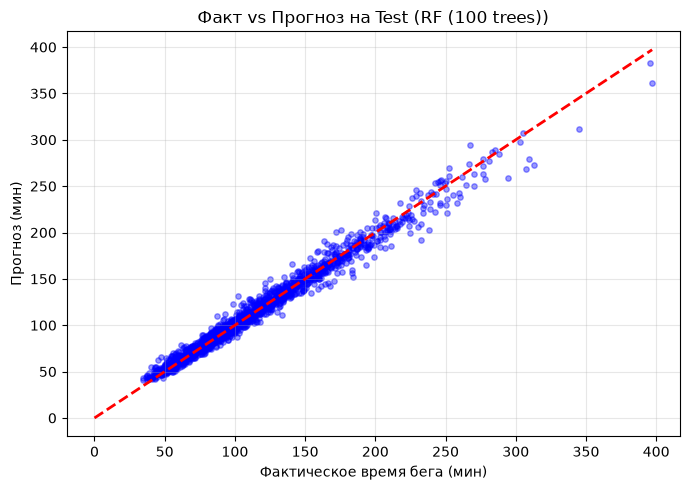

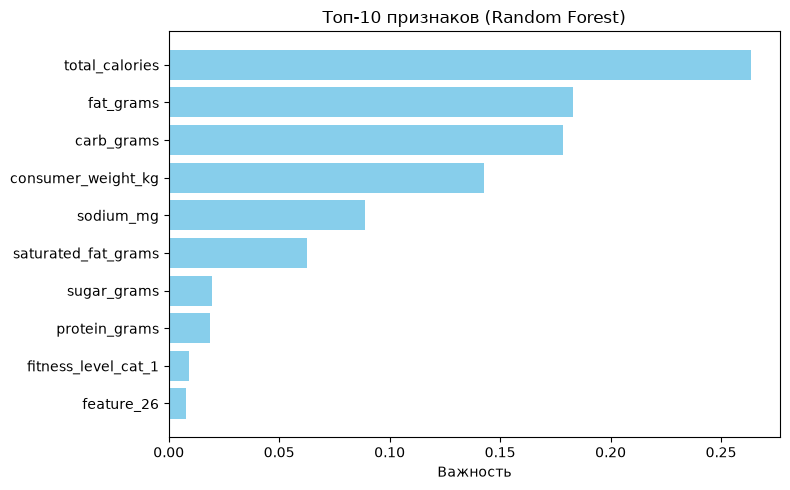

In [5]:
best_pipeline = models[best_model_name]
best_model = best_pipeline.fit(train_clean)

test_preds = best_model.transform(test_clean)
print("Test RMSE:", evaluator_rmse.evaluate(test_preds))
print("Test MAE:", evaluator_mae.evaluate(test_preds))
print("Test R2:", evaluator_r2.evaluate(test_preds))

test_pd = test_preds.select("label", "prediction").toPandas()

plt.figure(figsize=(7, 5))
plt.scatter(test_pd["label"], test_pd["prediction"], alpha=0.4, s=15, color="blue")
limit = max(test_pd["label"].max(), test_pd["prediction"].max())
plt.plot([0, limit], [0, limit], color="red", linestyle="--", linewidth=2)
plt.xlabel("Фактическое время бега (мин)")
plt.ylabel("Прогноз (мин)")
plt.title(f"Факт vs Прогноз на Test ({best_model_name})")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

if "RF" in best_model_name:
    rf_stage = best_model.stages[-1]
    importances = rf_stage.featureImportances.toArray()
    
    feature_names = num_features.copy()
    for c in cat_features:
        num_unique = train_clean.select(c).distinct().count()
        num_ohe = max(1, num_unique - 1)
        for i in range(num_ohe):
            feature_names.append(f"{c}_cat_{i}")
            
    feature_names = feature_names[:len(importances)]
    if len(feature_names) < len(importances):
        feature_names.extend([f"feature_{i}" for i in range(len(feature_names), len(importances))])
        
    fi_df = pd.DataFrame({"Feature": feature_names, "Importance": importances})
    fi_df = fi_df.sort_values("Importance", ascending=False).head(10)
    
    plt.figure(figsize=(8, 5))
    plt.barh(fi_df["Feature"][::-1], fi_df["Importance"][::-1], color="skyblue")
    plt.xlabel("Важность")
    plt.title("Топ-10 признаков (Random Forest)")
    plt.tight_layout()
    plt.show()

Проведена итоговая оценка выбранной модели на тестовой выборке, которая подтвердила стабильность результатов (RMSE = 7.61, R² = 0.979). График «Факт vs Прогноз» демонстрирует плотное прилегание точек к диагонали идеального предсказания. Анализ важности признаков подтвердил физический смысл модели: наибольший вклад в время бега вносят общая калорийность блюда, количество жиров и вес потребителя.

In [6]:
import os
import json

out_dir = "practice5_results"
os.makedirs(out_dir, exist_ok=True)

model_path = os.path.join(out_dir, "best_regression_model")
best_model.write().overwrite().save(model_path)

config = {
    "task": "Regression",
    "target_col": "running_burn_time_min",
    "best_model_name": best_model_name,
    "rmse_test": evaluator_rmse.evaluate(test_preds),
    "mae_test": evaluator_mae.evaluate(test_preds),
    "r2_test": evaluator_r2.evaluate(test_preds),
    "seed": 42
}

config_path = os.path.join(out_dir, "model_config.json")
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=4)

print(f"Модель и конфигурация сохранены в папку: {out_dir}")

spark.stop()

Модель и конфигурация сохранены в папку: practice5_results


### **Выводы по разделу 1**

1. Высокая объяснительная способность признаков. Итоговая модель достигла R2 = 0.979 на тестовой выборке. Это означает, что калорийность, макронутриентный состав блюда и биометрия человека объясняют 97,9% дисперсии времени, необходимого для сжигания калорий.

2. Нелинейность зависимости. Случайный лес (RMSE 7.73) превзошел линейную регрессию (RMSE 10.93) на валидации. Это доказывает, что связь между питательными веществами и временем тренировки не является чисто линейной.

3. Точность прогноза. Средняя абсолютная ошибка (MAE) лучшей модели на тесте составила всего 5.43 минуты. Для диапазона от 26 до 436 минут это означает, что модель способна предсказывать время тренировки с высокой практической точностью.

4. Ключевые факторы. Согласно графику важности признаков, наибольший вклад вносят total_calories (общая калорийность), fat_grams (жиры) и consumer_weight_kg (вес). Это подтверждает физический смысл: тяжелому человеку нужно меньше времени, чтобы сжечь то же количество калорий.

5. Устойчивость к переобучению. Метрики на валидации (RMSE 7.73, R2 0.979) и на тесте (RMSE 7.60, R2 0.979) практически идентичны. График «Факт vs Прогноз» показывает плотное прилегание точек к диагонали на всем диапазоне значений, что говорит об отсутствии переобучения.

### **Ограничения**

1. Искусственная природа данных. Слишком высокий R2 (почти 1.0) и идеально узкий разброс точек на графике указывают на то, что данные синтезированы строго по математическим формулам. На реальных биологических данных из-за метаболического шума и индивидуальных особенностей организма точность будет существенно ниже.

2. Отсутствие контекстных переменных. Модель показывает высокую точность только в рамках имеющихся признаков. Она не учитывает внешние факторы (температуру среды, усталость, пульсовые зоны), которые в реальности напрямую влияют на фактическое время сжигания калорий.